In [1]:
import pandas as pd

data = pd.read_csv("us-states.csv")

In [2]:
data = pd.read_csv(
    "us-states.csv",
    parse_dates=["date"],
    dtype={"fips": "string"}
)

# Sort within each state before calculating daily changes.
data = data.sort_values(["state", "date"]).reset_index(drop=True)

# Calculate differences separately for each state.
data["daily_cases"] = (
    data.groupby("state")["cases"]
    .diff()
    .astype("Int64")
)

data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61942 entries, 0 to 61941
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         61942 non-null  datetime64[ns]
 1   state        61942 non-null  object        
 2   fips         61942 non-null  string        
 3   cases        61942 non-null  int64         
 4   deaths       61942 non-null  int64         
 5   daily_cases  61886 non-null  Int64         
dtypes: Int64(1), datetime64[ns](1), int64(2), object(1), string(1)
memory usage: 2.9+ MB


,date,state,fips,cases,deaths,daily_cases
0,2020-03-13,Alabama,01,6,0,<NA>
1,2020-03-14,Alabama,01,12,0,6
2,2020-03-15,Alabama,01,23,0,11
3,2020-03-16,Alabama,01,29,0,6
4,2020-03-17,Alabama,01,39,0,10


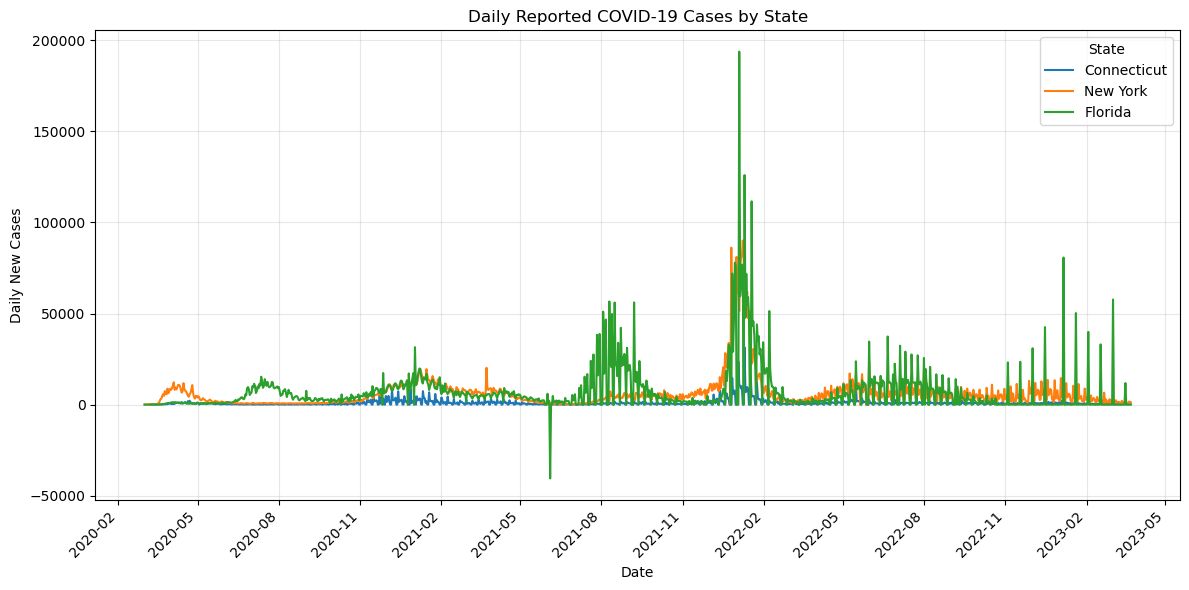

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


def plot_daily_cases(data, states):
    fig, ax = plt.subplots(figsize=(12, 6))

    for state in states:
        # Select one state and sort chronologically.
        state_data = (
            data.loc[data["state"] == state]
            .sort_values("date")
            .copy()
        )

        if state_data.empty:
            raise ValueError(f"State not found: {state}")

        ax.plot(
            state_data["date"],
            state_data["daily_cases"],
            label=state
        )

    ax.set_title("Daily Reported COVID-19 Cases by State")
    ax.set_xlabel("Date")
    ax.set_ylabel("Daily New Cases")
    ax.legend(title="State")
    ax.grid(alpha=0.3)

    # Keep date labels readable.
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    fig.tight_layout()
    return fig, ax

fig, ax = plot_daily_cases(
    data,
    ["Connecticut", "New York", "Florida"]
)

# Save the figure for the README.
fig.savefig("daily_cases.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
def find_peak_date(data, state):
    # Select the state and sort chronologically.
    state_data = (
        data.loc[data["state"] == state]
        .sort_values("date")
        .copy()
    )

    if len(state_data) < 2:
        raise ValueError(f"Not enough data for state: {state}")

    # idxmax() returns the row index of the maximum value.
    peak_index = state_data["daily_cases"].idxmax()
    return state_data.loc[peak_index, "date"]


def compare_peak_dates(data, state1, state2):
    peak1 = find_peak_date(data, state1)
    peak2 = find_peak_date(data, state2)

    days_apart = abs((peak1 - peak2).days)

    print(f"{state1}: {peak1:%Y-%m-%d}")
    print(f"{state2}: {peak2:%Y-%m-%d}")

    if peak1 < peak2:
        print(f"{state1} peaked {days_apart} days before {state2}.")
    elif peak2 < peak1:
        print(f"{state2} peaked {days_apart} days before {state1}.")
    else:
        print("Both states peaked on the same date.")

    return days_apart

# Test Function
peak_date = find_peak_date(data, "Connecticut")
print(f"Connecticut peak date: {peak_date:%Y-%m-%d}")

Connecticut peak date: 2022-01-10


In [7]:
def compare_peak_dates(data, state1, state2):
    peak1 = find_peak_date(data, state1)
    peak2 = find_peak_date(data, state2)

    days_apart = abs((peak1 - peak2).days)

    print(f"{state1}: {peak1:%Y-%m-%d}")
    print(f"{state2}: {peak2:%Y-%m-%d}")

    if peak1 < peak2:
        print(f"{state1} peaked {days_apart} days before {state2}.")
    elif peak2 < peak1:
        print(f"{state2} peaked {days_apart} days before {state1}.")
    else:
        print("Both states peaked on the same date.")

    return days_apart

# Test Function
days_apart = compare_peak_dates(data, "Connecticut", "Florida")

Connecticut: 2022-01-10
Florida: 2022-01-04
Florida peaked 6 days before Connecticut.


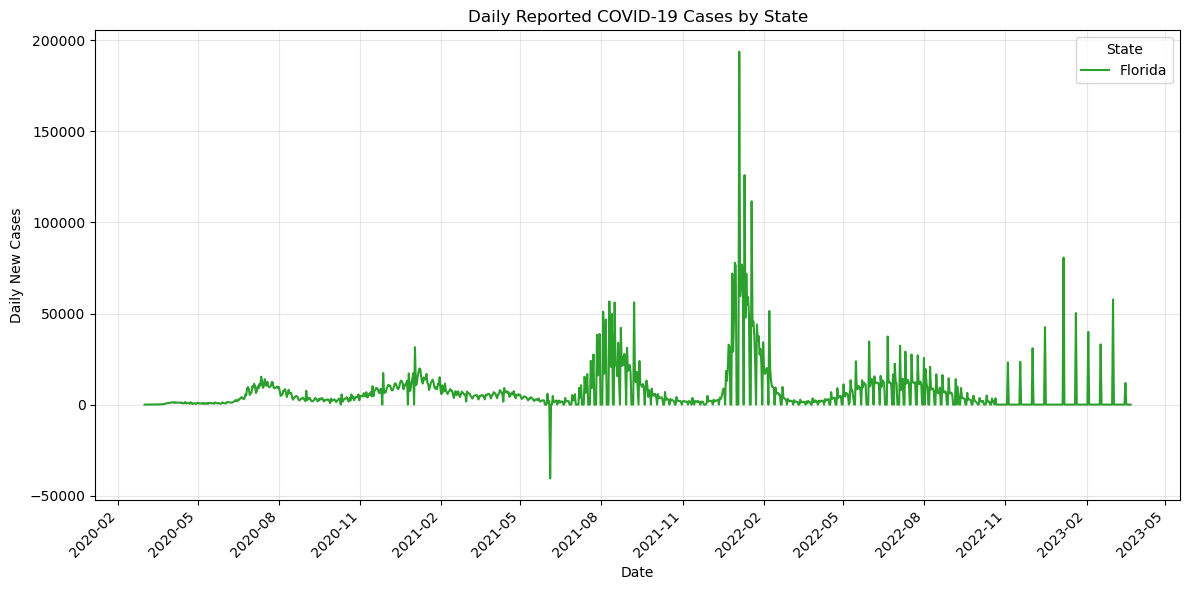

Ten largest daily increases:


,date,cases,daily_cases
11295,2022-01-04,4360178,193786
11301,2022-01-10,4759073,125996
11309,2022-01-18,5153539,111621
11662,2023-01-06,7350177,80749
11290,2021-12-30,4090000,77848
11298,2022-01-07,4563163,76887
11291,2021-12-31,4166392,76392
11287,2021-12-27,3936170,71957
11303,2022-01-12,4878524,71742
11299,2022-01-08,4633077,69914


Records around Florida's peak:


,date,cases,daily_cases
11288,2021-12-28,3965229,29059
11289,2021-12-29,4012152,46923
11290,2021-12-30,4090000,77848
11291,2021-12-31,4166392,76392
11292,2022-01-01,4166392,0
11293,2022-01-02,4166392,0
11294,2022-01-03,4166392,0
11295,2022-01-04,4360178,193786
11296,2022-01-05,4419665,59487
11297,2022-01-06,4486276,66611


Days with zero reported increase: 287
Days with negative revisions: 1


In [9]:
# Plot Florida using the function from 1b.
fig, ax = plot_daily_cases(data, ["Florida"])
ax.lines[0].set_color("tab:green")
ax.legend(title="State")
fig.savefig("florida_daily_cases.png", dpi=150, bbox_inches="tight")
plt.show()

# Prepare Florida's daily case counts.
florida = (
    data.loc[data["state"] == "Florida"]
    .sort_values("date")
    .copy()
)


# Inspect the largest daily increases.
print("Ten largest daily increases:")
display(
    florida.nlargest(10, "daily_cases")[
        ["date", "cases", "daily_cases"]
    ]
)

# Inspect a two-week window around the largest increase.
peak_date = find_peak_date(data, "Florida")

window = florida.loc[
    florida["date"].between(
        peak_date - pd.Timedelta(days=7),
        peak_date + pd.Timedelta(days=7)
    )
]

print("Records around Florida's peak:")
display(window[["date", "cases", "daily_cases"]])

# Count zero and negative changes, excluding the first missing difference.
valid_daily = florida["daily_cases"].dropna()

print(f"Days with zero reported increase: {(valid_daily == 0).sum()}")
print(f"Days with negative revisions: {(valid_daily < 0).sum()}")